IMPORTING LIBRARIES

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from xgboost import XGBRegressor


LOADING DATA AND SPLITTING

In [2]:
df = pd.read_csv("../data/processed.csv")

X = df.drop(columns=["selling_price"])
y = df["selling_price"]

# same random_state = same split every time
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)
X_train.head()

train: (12189, 11)  test: (3048, 11)


,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats
14337,audi,a6,4,23000,dealer,diesel,automatic,18.53,1968,187.74,5
14165,renault,kwid,4,15000,individual,petrol,manual,23.01,999,67.00,5
15153,maruti,swift,12,53000,dealer,petrol,manual,16.10,1298,88.20,5
4077,hyundai,i20,7,44000,individual,petrol,manual,18.50,1197,82.85,5
15027,honda,city,5,45904,dealer,petrol,automatic,18.00,1497,117.30,5


BUILDING THE PIPELINE

In [3]:
number_cols = ["vehicle_age", "km_driven", "mileage", "engine", "max_power",
               "seats"]
onehot_cols = ["seller_type", "fuel_type", "transmission_type"]
target_enc_cols = ["brand", "model"]
cv_generator = KFold(n_splits=5, shuffle=True, random_state=42)
def make_pipeline(model, scale=False):
    number_step = StandardScaler() if scale else "passthrough"
    prep = ColumnTransformer([
        ("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_cols),
        ("target_enc", TargetEncoder(cv=cv_generator), target_enc_cols),
        ("numbers", number_step, number_cols),
    ])
    pipe = Pipeline([("prep", prep), ("model", model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

models = {
    "Linear Regression": make_pipeline(LinearRegression(), scale=True),
    "Random Forest": make_pipeline(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
    "XGBoost": make_pipeline(XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=42)),
}

COMPARING MODELS (cross-validation on the train data only)

In [4]:
folds = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"r2": "r2",
           "mae": "neg_mean_absolute_error",
           "mape": "neg_mean_absolute_percentage_error"}

rows = []
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=folds, scoring=scoring)
    rows.append({"model": name,
                 "R2": scores["test_r2"].mean(),
                 "MAE (Rs)": -scores["test_mae"].mean(),
                 "avg % error": -scores["test_mape"].mean() * 100})

results = pd.DataFrame(rows).sort_values("avg % error").reset_index(drop=True)
results.round(2)

,model,R2,MAE (Rs),avg % error
0,XGBoost,0.89,96992.58,12.57
1,Random Forest,0.87,100589.85,12.92
2,Linear Regression,0.80,132839.08,16.27


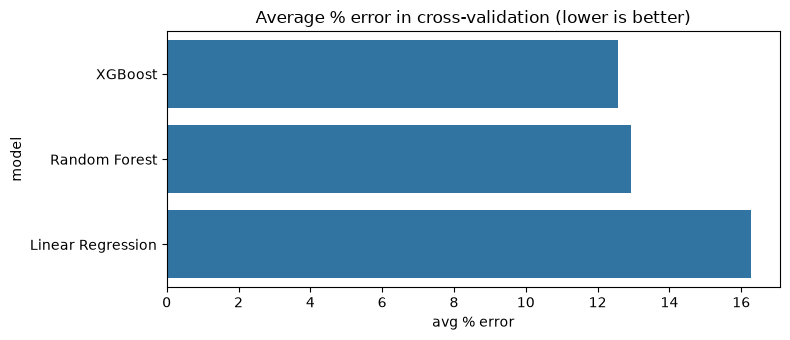

In [5]:
plt.figure(figsize=(8, 3.5))
sns.barplot(data=results, y="model", x="avg % error")
plt.title("Average % error in cross-validation (lower is better)")
plt.tight_layout()
plt.show()

TESTING THE BEST MODEL ON THE TEST DATA (only once)

In [6]:
best_name = results.loc[0, "model"]
best_model = models[best_name]
best_model.fit(X_train, y_train)

print("Best model:", best_name)
pred = best_model.predict(X_test)
test_scores = {"R2": r2_score(y_test, pred),
               "MAE (Rs)": mean_absolute_error(y_test, pred),
               "avg % error": mean_absolute_percentage_error(y_test, pred) * 100}
pd.Series(test_scores).round(2).to_frame("test score")

Best model: XGBoost


,test score
R2,0.94
MAE (Rs),91995.57
avg % error,12.62


In [7]:
errors = np.abs(pred - y_test) / y_test * 100
print(f"Average error: {errors.mean():.1f}%   Median error: {errors.median():.1f}%")
for limit in (10, 20, 25):
    print(f"Within {limit}%: {(errors <= limit).mean() * 100:.0f}% of cars")

Average error: 12.6%   Median error: 9.5%
Within 10%: 52% of cars
Within 20%: 82% of cars
Within 25%: 89% of cars


Predicted vs real price

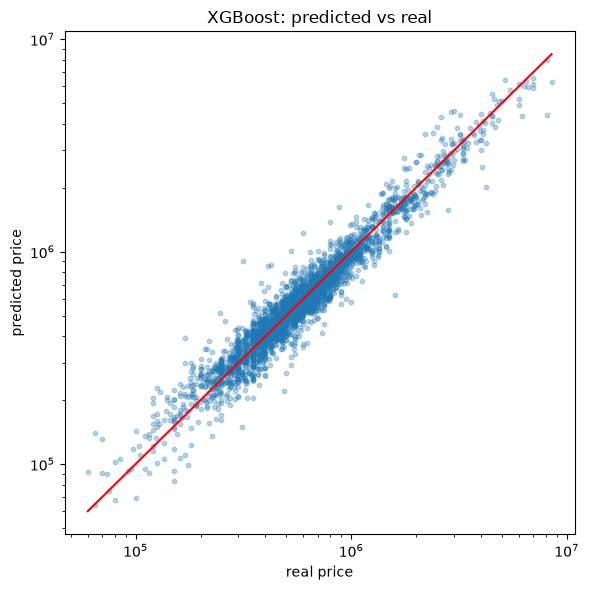

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3, s=10)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color="red")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("real price"); plt.ylabel("predicted price")
plt.title(f"{best_name}: predicted vs real")
plt.tight_layout()
plt.show()

Where does the model make bigger mistakes? (% error by price range)

In [9]:
errors = pd.DataFrame({"real": y_test, "pred": pred})
errors["% error"] = (errors["pred"] - errors["real"]).abs() / errors["real"] * 100
errors["price range"] = pd.cut(errors["real"], [0, 3e5, 6e5, 1e6, 2e6, 1e8],
                               labels=["< 3 lakh", "3-6 lakh", "6-10 lakh", "10-20 lakh", "> 20 lakh"])
errors.groupby("price range", observed=True)["% error"].agg(["mean", "median", "count"]).round(1)

,mean,median,count
price range,,,
< 3 lakh,18.2,14.1,406
3-6 lakh,12.5,9.6,1316
6-10 lakh,10.0,7.9,841
10-20 lakh,12.2,10.1,336
> 20 lakh,13.8,9.9,149
